# 02 · Normalization, RoPE and attention (MHA → GQA → MLA)

**What you will learn**
- RMSNorm vs LayerNorm and why pre-norm won
- RoPE: how rotating q/k encodes *relative* position, verified numerically
- Scaled dot-product attention computed by hand and checked against PyTorch's fused kernel
- Multi-head → grouped-query → multi-head-latent attention and what each does to the KV-cache
- KV-cache correctness: incremental decoding must equal the full forward pass

**Source:** `llmsuite/layers.py`.

In [1]:
import os, sys, math, time, tempfile
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llmsuite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # notebooks live in notebooks/<topic>/, so climb up to the repo root
sys.path.insert(0, ROOT)                            # so that `import llmsuite` works from the notebook
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from llmsuite.utils import seed_everything, get_device, count_params, human, show_mask
seed_everything(0)
device = get_device()
print("torch", torch.__version__, "| device", device)

torch 2.14.1+cu130 | device cuda


## 1. RMSNorm

LayerNorm re-centers and re-scales each token vector; RMSNorm only re-scales:

$$\text{RMSNorm}(x) = \gamma \odot \frac{x}{\sqrt{\tfrac{1}{C}\sum_i x_i^2 + \epsilon}}$$

Scale invariance is what stabilizes training; centering adds nothing measurable (Zhang & Sennrich 2019). One reduction less, no bias, equally good → the standard in Llama / Mistral / DeepSeek / Gemma.

In [2]:
from llmsuite.layers import RMSNorm

x = torch.randn(2, 5, 16) * 7 + 3                      # deliberately large scale and offset
ln, rms = nn.LayerNorm(16), RMSNorm(16)
for name, y in [("input", x), ("LayerNorm", ln(x)), ("RMSNorm", rms(x))]:
    print(f"{name:10s} mean {y.mean():6.2f}   rms {y.pow(2).mean().sqrt():5.2f}")
print("matches torch.nn.RMSNorm:", torch.allclose(rms(x), nn.RMSNorm(16)(x), atol=1e-5))
print("scale invariance: RMSNorm(3x) == RMSNorm(x):", torch.allclose(rms(3 * x), rms(x), atol=1e-5))

input      mean   3.16   rms  7.60
LayerNorm  mean   0.00   rms  1.00
RMSNorm    mean   0.42   rms  1.00
matches torch.nn.RMSNorm: True
scale invariance: RMSNorm(3x) == RMSNorm(x): True


## 2. RoPE — rotary position embeddings

Attention is permutation-invariant, so position must be injected. RoPE rotates the query at position *m* by angle *mθ* and the key at *n* by *nθ*. Because rotations compose by adding angles:

$$(R(m\theta)q)^\top (R(n\theta)k) = q^\top R((n-m)\theta)\,k$$

**The score depends only on the distance n − m.** Each head's `Dh` dims are split into `Dh/2` pairs with frequencies $\theta_i = \text{base}^{-2i/D_h}$: fast "hands" for local resolution, slow ones for long range.

In [3]:
from llmsuite.layers import precompute_freqs_cis, apply_rope

Dh = 64
freqs = precompute_freqs_cis(Dh, max_seq_len=1024)              # (T, Dh/2) complex
print("freqs_cis:", freqs.shape, freqs.dtype)

q, k = torch.randn(Dh), torch.randn(Dh)
def score(m, n):
    qm = apply_rope(q.view(1, 1, 1, Dh), freqs, start_pos=m)
    kn = apply_rope(k.view(1, 1, 1, Dh), freqs, start_pos=n)
    return (qm * kn).sum().item()

print("norm preserved:", torch.allclose(q.norm(), apply_rope(q.view(1,1,1,Dh), freqs, 7).norm(), atol=1e-5))
print(f"distance 5 at (5,0):     {score(5, 0):+.4f}")
print(f"distance 5 at (105,100): {score(105, 100):+.4f}")
print(f"distance 5 at (905,900): {score(905, 900):+.4f}   <- identical: only relative position matters")

freqs_cis: torch.Size([1024, 32]) torch.complex64
norm preserved: True
distance 5 at (5,0):     +3.3047
distance 5 at (105,100): +3.3047
distance 5 at (905,900): +3.3047   <- identical: only relative position matters


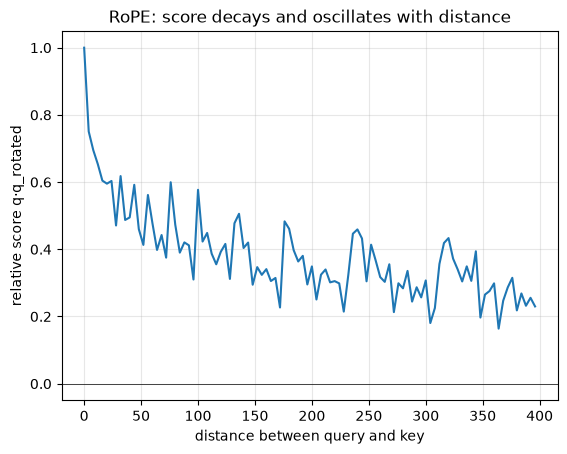

In [4]:
import matplotlib.pyplot as plt
# Dot product of a vector with a rotated copy of itself, as a function of distance. The decay is RoPE's built-in locality bias.
ds = list(range(0, 400, 4)); curve = []
for d in ds:
    vals = []
    for _ in range(64):
        v = torch.randn(Dh)
        a = apply_rope(v.view(1,1,1,Dh), freqs, d); b = apply_rope(v.view(1,1,1,Dh), freqs, 0)
        vals.append((a * b).sum().item() / (v @ v).item())
    curve.append(sum(vals) / len(vals))
plt.plot(ds, curve); plt.axhline(0, color="k", lw=.5)
plt.xlabel("distance between query and key"); plt.ylabel("relative score q·q_rotated"); plt.title("RoPE: score decays and oscillates with distance"); plt.grid(alpha=.3); plt.show()

### Context extension
Frequencies are fixed for the training length. Beyond it, the slow pairs reach angles never seen. Llama-3.1 style scaling divides the *low* frequencies by a factor and leaves the high ones alone (`scaling={"factor": 8, "orig_len": 8192}`) — only `precompute_freqs_cis` changes, the model does not.

In [5]:
f_base = precompute_freqs_cis(64, 16)
f_scaled = precompute_freqs_cis(64, 16, scaling={"factor": 8.0, "orig_len": 8192})
a_base, a_scaled = f_base[1].angle(), f_scaled[1].angle()
print("high-frequency pairs unchanged:", torch.allclose(a_base[:8], a_scaled[:8]))
print("low-frequency pairs divided by 8:", torch.allclose(a_base[-7:] / 8, a_scaled[-7:], atol=1e-6))   # the 7 slowest pairs are fully stretched, while pairs ~21-24 sit in the smooth transition

high-frequency pairs unchanged: True
low-frequency pairs divided by 8: True


## 3. Scaled dot-product attention, by hand

$$\text{Attn}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{D_h}} + M\right)V$$

- `QKᵀ`: affinity of every query with every key, shape `(T, T)`
- `/√Dh`: keeps logits O(1) so the softmax does not saturate
- `M`: causal mask, `-inf` above the diagonal → exactly zero weight on future tokens
- the output of each token is a weighted average of the values it attends to

In [6]:
def attention_manual(q, k, v, verbose=False):
    B, H, T, Dh = q.shape
    scores = q @ k.transpose(-2, -1) / math.sqrt(Dh)
    allowed = torch.tril(torch.ones(T, T, dtype=torch.bool))
    scores = scores.masked_fill(~allowed, float("-inf"))
    w = scores.softmax(-1)
    if verbose:
        print("attention weights (batch 0, head 0) — rows sum to 1, upper triangle is 0:")
        print(w[0, 0].round(decimals=2))
    return w @ v

q, k, v = torch.randn(3, 1, 1, 5, 8)
out = attention_manual(q, k, v, verbose=True)
ref = F.scaled_dot_product_attention(q, k, v, is_causal=True)
print("\nmatches F.scaled_dot_product_attention:", torch.allclose(out, ref, atol=1e-5))

attention weights (batch 0, head 0) — rows sum to 1, upper triangle is 0:
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4700, 0.5300, 0.0000, 0.0000, 0.0000],
        [0.0500, 0.8800, 0.0700, 0.0000, 0.0000],
        [0.5400, 0.1200, 0.2200, 0.1100, 0.0000],
        [0.2900, 0.3200, 0.2300, 0.1500, 0.0200]])

matches F.scaled_dot_product_attention: True


## 4. MHA → GQA → MLA: the KV-cache problem

During generation every past token's **k** and **v** are cached per layer. For Llama-2-70B (80 layers, 64 heads × 128 dims) that is 2.6 MB per token in fp16: with 4k tokens of context, **10 GB per sequence**. The cache, not compute, limits how many users a GPU serves.

| | k/v heads | cache per token per layer | used by |
|---|---|---|---|
| MHA | H | 2·H·Dh | GPT-2/3 |
| MQA | 1 | 2·Dh | PaLM, Falcon |
| **GQA** | Hkv (H/4–H/8) | 2·Hkv·Dh | Llama 2/3, Mistral, Qwen |
| **MLA** | latent | r + Dr (512 + 64) | DeepSeek V2/V3/R1 |

`GroupedQueryAttention` implements all of the first three via `n_kv_heads`; `MultiHeadLatentAttention` compresses k and v of *all* heads into one low-rank latent and caches that.

In [7]:
from llmsuite.layers import GroupedQueryAttention, MultiHeadLatentAttention

C, H = 128, 8
freqs = precompute_freqs_cis(C // H, 256)
variants = {
    "MHA (8 kv heads)": GroupedQueryAttention(C, H, n_kv_heads=8),
    "GQA (2 kv heads)": GroupedQueryAttention(C, H, n_kv_heads=2),
    "MQA (1 kv head) ": GroupedQueryAttention(C, H, n_kv_heads=1),
    "MLA (rank 16)   ": MultiHeadLatentAttention(C, H, kv_lora_rank=16, qk_nope_dim=12, qk_rope_dim=4, v_dim=16),
}
x = torch.randn(2, 10, C)
for name, m in variants.items():
    y = m(x, freqs)
    print(f"{name}  params {count_params(m):>7,}  kv-cache/token/layer {m.kv_cache_bytes_per_token():>5} bytes  out {tuple(y.shape)}")

# For reference, these are DeepSeek-V3's actual sizes:
print(f"\nDeepSeek-V3 per token per layer: MHA(128 heads x 128) = {2*128*128*2:,} bytes | MLA = {(512+64)*2:,} bytes  (÷{2*128*128/(512+64):.0f})")

MHA (8 kv heads)  params  65,536  kv-cache/token/layer   512 bytes  out (2, 10, 128)
GQA (2 kv heads)  params  40,960  kv-cache/token/layer   128 bytes  out (2, 10, 128)
MQA (1 kv head)   params  36,864  kv-cache/token/layer    64 bytes  out (2, 10, 128)
MLA (rank 16)     params  38,928  kv-cache/token/layer    40 bytes  out (2, 10, 128)

DeepSeek-V3 per token per layer: MHA(128 heads x 128) = 65,536 bytes | MLA = 1,152 bytes  (÷57)


## 5. KV-cache correctness

The cache must not change the result. We compare the full forward pass with prefill (8 tokens) + 4 single-token decode steps.
Note the RoPE position bookkeeping: a new token at position `t` is rotated with `freqs_cis[t]`, cached keys keep their original rotation, and the angle *difference* comes out right automatically.

In [8]:
for name, attn in [("GQA", variants["GQA (2 kv heads)"]), ("MLA", variants["MLA (rank 16)   "])]:
    x = torch.randn(1, 12, C)
    y_full = attn(x, freqs)                                            # training-style forward pass without a cache
    attn.clear_cache()
    parts = [attn(x[:, :8], freqs, start_pos=0)]                       # prefill
    for t in range(8, 12):
        parts.append(attn(x[:, t:t+1], freqs, start_pos=t))            # then decode one token at a time
    y_inc = torch.cat(parts, dim=1)
    print(f"{name}: full == prefill+decode:", torch.allclose(y_full, y_inc, atol=1e-4), f"(max diff {(y_full - y_inc).abs().max():.2e})")

GQA: full == prefill+decode: True (max diff 1.19e-07)
MLA: full == prefill+decode: True (max diff 1.79e-07)


## 6. Evaluation: attention variants on a real objective

Metrics so far were structural (parameters, cache bytes, equivalence). The question that matters: **does GQA/MLA hurt modeling quality?** We train tiny LMs with each variant on the same synthetic corpus for the same number of steps and compare validation perplexity. (At this scale differences are noisy — the point is the methodology; run longer / larger to get reliable comparisons.)

In [9]:
from llmsuite.model import ModelConfig, TransformerLM
from llmsuite.data import synthetic_structured_corpus, train_val_split
from llmsuite.training import TrainConfig, train_lm
from llmsuite.evaluation import perplexity

data = synthetic_structured_corpus(n_tokens=120_000, vocab=512)
train_data, val_data = train_val_split(data)
tcfg = TrainConfig(steps=250, batch_size=32, block_size=64, max_lr=3e-3, warmup=25, eval_every=250, log=False)

results = {}
for name, kw in {"MHA": dict(attn="gqa", n_kv_heads=8), "GQA-2": dict(attn="gqa", n_kv_heads=2),
                 "MQA": dict(attn="gqa", n_kv_heads=1), "MLA": dict(attn="mla", kv_lora_rank=16, qk_nope_dim=12, qk_rope_dim=4, v_dim=16)}.items():
    seed_everything(0)
    model = TransformerLM(ModelConfig(vocab_size=512, d_model=128, n_layers=4, n_heads=8, **kw))
    res = train_lm(model, train_data, val_data, tcfg, device)
    ppl = perplexity(model, val_data, block_size=64, n_batches=20, device=device)
    results[name] = (ppl, model.kv_cache_bytes_per_token(), res.wall_time)
    print(f"{name:6s} val ppl {ppl:7.2f} | kv-cache {model.kv_cache_bytes_per_token():5d} B/token | {res.wall_time:.1f}s")

MHA    val ppl    2.65 | kv-cache  2048 B/token | 5.9s


GQA-2  val ppl    2.64 | kv-cache   512 B/token | 5.5s


MQA    val ppl    2.64 | kv-cache   256 B/token | 5.6s


MLA    val ppl    2.65 | kv-cache   160 B/token | 7.6s


**How to read this:** perplexity should be similar across variants (GQA ≈ MHA is the published finding; MLA ≥ MHA in DeepSeek's experiments) while the cache column shrinks 4–10×. If one variant is clearly worse here, increase `steps` before concluding — 250 steps on a toy corpus is a smoke test, not a benchmark.

**Next:** `03_efficient_attention.ipynb` — what to do when the sequence gets long.